# Statistical Modelling

In [ ]:
import warnings
from pathlib import Path

warnings.filterwarnings(
    "ignore",
    message="PySpark does not yet fully support pandas"
)

import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import (
    OneHotEncoder,
    StandardScaler,
    StringIndexer,
    VectorAssembler,
)
from pyspark.ml.regression import (
    GBTRegressor,
    GeneralizedLinearRegression,
    LinearRegression,
    RandomForestRegressor,
)
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder.appName("Airport Travel-Time Modelling")
    .config("spark.sql.session.timeZone", "America/New_York")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

In [ ]:
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name in {"code", "notebooks"}:
      PROJECT_ROOT = CURRENT_DIR.parent
else:
      PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "plots"
TABLES_DIR = PROJECT_ROOT / "tables"

FINAL_DATA_PATH = (PROCESSED_DIR / "airport_weather_trips_2024_h1")

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

analysis_data = spark.read.parquet(str(FINAL_DATA_PATH))

analysis_trip_count = analysis_data.count()

print(f"Modelling dataset: "
      f"{analysis_trip_count:,} rows x "
      f"{len(analysis_data.columns)} columns")

## Expanding-Window Evaluation

In [ ]:
VALIDATION_WINDOWS = [
    {"name": "April validation",
    "training_end": "2024-04-01 00:00:00",
    "evaluation_end": "2024-05-01 00:00:00"
    },
    {"name": "May validation",
    "training_end": "2024-05-01 00:00:00",
    "evaluation_end": "2024-06-01 00:00:00"
    }
]

validation_datasets = {}

for window in VALIDATION_WINDOWS:
    training_data = analysis_data.filter(
        F.col("tpep_pickup_datetime") < window["training_end"]
    )
    validation_data = analysis_data.filter(
        (F.col("tpep_pickup_datetime") >= window["training_end"]) &
        (F.col("tpep_pickup_datetime") < window["evaluation_end"])
    )
    
    training_count = training_data.count()
    validation_count = validation_data.count()
    
    assert training_count > 0
    assert validation_count > 0
    
    validation_datasets[window["name"]] = {
        "training" : training_data,
        "validation" : validation_data
    }
    
    print(window["name"])
    print(f"  Training trips: {training_count:,}")
    print(f"  Evaluation trips: {validation_count:,}")
    
final_training_data = analysis_data.filter(F.col("tpep_pickup_datetime") < "2024-06-01 00:00:00")    

final_test_data = analysis_data.filter(
    (F.col("tpep_pickup_datetime") >= "2024-06-01 00:00:00") &
    (F.col("tpep_pickup_datetime") < "2024-07-01 00:00:00")
)

final_training_count = final_training_data.count()
final_test_count = final_test_data.count()

assert final_training_count > 0
assert final_test_count > 0

print("June final test")
print(f"  Training trips: {final_training_count:,}")
print(f"  Test trips held out: {final_test_count:,}")

## Model Inputs and Feature Pipeline

In [ ]:
categorical_features = [
    "airport",
    "pickup_zone",
    "pickup_hour_category",
    "pickup_day_category"
]

numerical_features = [
    "temperature_f",
    "precipitation_missing",
    "precipitation_for_model",
    "visibility_miles",
    "wind_speed_mph",
    "relative_humidity",
    "precipitation_event",
    "snow_event",
    "fog_or_low_visibility",
    "weather_code_available"
]

def prepare_model_data(dataframe):
    prepared_data = dataframe.withColumn(
        "weather_code_available",
        (F.col("present_weather").isNotNull() &
        (F.trim(F.col("present_weather")) != "")
        ).cast("double")
    )
    
    return prepared_data.select(
        "tpep_pickup_datetime",
        
        F.col("trip_duration_minutes").cast("double").alias("label"),
        
        "airport",
        "pickup_zone",
        "pickup_hour",
        "pickup_day_of_week",
        
        F.col("pickup_hour").cast("string").alias("pickup_hour_category"),
        F.col("pickup_day_of_week").cast("string").alias("pickup_day_category"),
        
        *[F.col(column).cast("double").alias(column) for column in numerical_features]
    )
    
prepared_validation_datasets = {}

for window_name, datasets in validation_datasets.items():
    prepared_validation_datasets[window_name] = {
        "training" : prepare_model_data(datasets["training"]),
        "validation" : prepare_model_data(datasets["validation"])
    }

In [ ]:
indexed_columns = [f"{column}_index" for column in categorical_features]
encoded_columns = [f"{column}_encoded" for column in categorical_features]

indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=indexed_column,
        handleInvalid="keep",
        stringOrderType="alphabetAsc"
    )
    for column, indexed_column in zip(categorical_features, indexed_columns)
]
    
encoder = OneHotEncoder(
    inputCols=indexed_columns,
    outputCols=encoded_columns,
    handleInvalid="keep",
    dropLast=True
)
    
full_feature_assembler = VectorAssembler(
    inputCols=(encoded_columns + numerical_features),
    outputCol="features",
    handleInvalid="error"
)
    
no_weather_feature_assembler = VectorAssembler(
    inputCols=encoded_columns,
    outputCol="features_no_weather",
    handleInvalid="error"
)

full_feature_scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withStd=True,
    withMean=False
)

no_weather_feature_scaler = StandardScaler(
    inputCol="features_no_weather",
    outputCol="scaled_features_no_weather",
    withStd=True,
    withMean=False
)

feature_pipeline = Pipeline(
    stages=(indexers + [encoder, full_feature_assembler,
                        no_weather_feature_assembler, full_feature_scaler,
                        no_weather_feature_scaler])
)

In [ ]:
evaluation_context_columns = [
    "tpep_pickup_datetime",
    "label",
    "airport",
    "pickup_zone",
    "pickup_hour",
    "pickup_day_of_week",
    "temperature_f",
    "precipitation_missing",
    "precipitation_for_model",
    "visibility_miles",
    "wind_speed_mph",
    "relative_humidity",
    "precipitation_event",
    "snow_event",
    "fog_or_low_visibility",
]

def prepare_feature_window(training_data, evaluation_data, window_name):
    pipeline_model = feature_pipeline.fit(training_data)
    
    training_features = (pipeline_model.transform(training_data)
                        .select("label", "features", "scaled_features",
                                "features_no_weather","scaled_features_no_weather").cache())
    
    evaluation_features = (pipeline_model.transform(evaluation_data)
                        .select(*evaluation_context_columns, "features",
                                "scaled_features", "features_no_weather",
                                "scaled_features_no_weather").cache())
    
    training_count = training_features.count()
    evaluation_count = evaluation_features.count()
    
    print(f"{window_name} training features: {training_count:,}")
    print(f"{window_name} evaluation features: {evaluation_count:,}")
    
    return {"pipeline_model": pipeline_model,
            "training": training_features,
            "evaluation": evaluation_features}

## Candidate Models

In [ ]:
candidate_models = {
    "Ridge Regression": LinearRegression(
        featuresCol= "scaled_features",
        labelCol="label",
        predictionCol="prediction",
        regParam=0.1,
        elasticNetParam=0.0,
        solver="l-bfgs",
        maxIter=100
    ),
    
    "Gamma GLR": GeneralizedLinearRegression(
        featuresCol= "scaled_features",
        labelCol="label",
        predictionCol="prediction",
        family="gamma",
        link="log",
        regParam=0.1,
        maxIter=50
    ),
    
    "Random Forest": RandomForestRegressor(
        featuresCol="features",
        labelCol="label",
        predictionCol="prediction",
        numTrees=40,
        maxDepth=7,
        minInstancesPerNode=10,
        subsamplingRate=0.8,
        seed=42
    ),
    
    "Gradient-Boosted Trees": GBTRegressor(
        featuresCol= "features",
        labelCol="label",
        predictionCol="prediction",
        maxIter=30,
        maxDepth=5,
        minInstancesPerNode=10,
        stepSize=0.08,
        subsamplingRate=0.8,
        seed=42
    )
}

## Evaluation Metrics

In [ ]:
evaluation_metrics = {
    "MAE" : RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="mae"
    ),
    
    "RMSE" : RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="rmse"
    ),
    
    "R2" : RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="r2"
    )
}

def evaluate_predictions(predictions):
    metric_results = {
        metric_name : evaluator.evaluate(predictions)
        for metric_name, evaluator in evaluation_metrics.items()
    }
    
    mean_underprediction = (predictions.agg(F.avg(F.col("label") - F.col("prediction")
    ).alias("mean_underprediction")).first()["mean_underprediction"])
    
    metric_results["Mean Underprediction"] = mean_underprediction
    
    return metric_results

In [ ]:
prediction_output_columns = evaluation_context_columns + ["prediction"]

def fit_and_evaluate_model (model_name, estimator, training_data, evaluation_data):
        print(f"Fitting {model_name}...")
        fitted_model = estimator.fit(training_data)
        
        predictions = (fitted_model
                        .transform(evaluation_data)
                        .select(*prediction_output_columns)
                        .cache())
        
        metrics = evaluate_predictions(predictions)
        
        return {"model": fitted_model,
                "predictions": predictions,
                "metrics": metrics}

In [ ]:
def create_model_summary(model_results, decimal_places=3):
    summary_rows = []
    
    for model_name, result in model_results.items():
        metrics = result["metrics"]
        
        summary_rows.append((
            model_name,
            float(metrics["MAE"]),
            float(metrics["RMSE"]),
            float(metrics["R2"]),
            float(metrics["Mean Underprediction"]))
        )
        
    summary = spark.createDataFrame(summary_rows,
                                    ["model", "mae", "rmse", "r2",
                                    "mean_underprediction"])
    return (summary.select("model",
            F.round("mae", decimal_places).alias("mae"),
            F.round("rmse", decimal_places).alias("rmse"),
            F.round("r2", decimal_places).alias("r2"),
            F.round("mean_underprediction", decimal_places).alias("mean_underprediction")
        ).orderBy("mae")
    )

In [ ]:
def calculate_prediction_errors(model_results):
    combined_errors = None
    
    for model_name, result in model_results.items():
        model_errors = (result["predictions"]
                        .select(F.lit(model_name).alias("model"), *prediction_output_columns)
                        .withColumn("prediction_error", F.col("label") - F.col("prediction")))
        
        if combined_errors is None:
            combined_errors = model_errors
        else:
            combined_errors = (combined_errors.unionByName(model_errors))
            
    return combined_errors

### April Model Screening

In [ ]:
april_data = prepared_validation_datasets["April validation"]

april_feature_data = prepare_feature_window(
        training_data=april_data["training"],
        evaluation_data=april_data["validation"],
        window_name="April"
)

In [ ]:
april_model_results = {}

for model_name, estimator in candidate_models.items():
    april_model_results[model_name] = (
        fit_and_evaluate_model(
            model_name=model_name, estimator=estimator,
            training_data=april_feature_data["training"],
            evaluation_data=april_feature_data["evaluation"]
        )
    ) 

april_screening_table = create_model_summary(april_model_results)

### May Model Validation

In [ ]:
# Release the cached April datasets before preparing May data
april_feature_data["training"].unpersist()
april_feature_data["evaluation"].unpersist()

may_data = prepared_validation_datasets["May validation"]

may_feature_data = prepare_feature_window(
    training_data=may_data["training"],
    evaluation_data=may_data["validation"],
    window_name="May"
)

In [ ]:
selected_model_names = ["Gamma GLR", "Gradient-Boosted Trees"]

may_model_results = {}

for model_name in selected_model_names:
    may_model_results[model_name] = (
        fit_and_evaluate_model(model_name=model_name, estimator=candidate_models[model_name],
                                training_data=may_feature_data["training"],
                                evaluation_data=may_feature_data["evaluation"]))

may_evaluation_summary = create_model_summary(may_model_results)

In [ ]:
# Release predictions from models excluded
for model_name in ["Ridge Regression", "Random Forest"]:
    april_model_results[model_name]["predictions"].unpersist()

### Weather Feature Removal

In [ ]:
no_weather_estimators = {"Gamma GLR": candidate_models["Gamma GLR"].copy({
    candidate_models["Gamma GLR"].featuresCol:"scaled_features_no_weather"}),
                        "Gradient-Boosted Trees": candidate_models["Gradient-Boosted Trees"].copy({
    candidate_models["Gradient-Boosted Trees"].featuresCol:"features_no_weather"})
}

no_weather_model_results = {}

for model_name, estimator in no_weather_estimators.items():
    no_weather_model_results[model_name] = (
        fit_and_evaluate_model(model_name=f"{model_name} without weather",
                                estimator=estimator,
                                training_data=may_feature_data["training"],
                                evaluation_data=may_feature_data["evaluation"])
    )

In [ ]:
weather_removal_results = {
    "Gamma GLR - full weather": may_model_results["Gamma GLR"],
    "Gamma GLR - without weather": no_weather_model_results["Gamma GLR"],
    
    "GBT - full weather": may_model_results["Gradient-Boosted Trees"],
    "GBT - without weather": no_weather_model_results["Gradient-Boosted Trees"]
}

weather_removal_summary = create_model_summary(weather_removal_results)

In [ ]:
#Release temporary weather-removal predictions

for result in no_weather_model_results.values():
    result["predictions"].unpersist()
    
# May feature vectors are no longer needed
may_feature_data["training"].unpersist()
may_feature_data["evaluation"].unpersist()

DataFrame[tpep_pickup_datetime: timestamp_ntz, label: double, airport: string, pickup_zone: string, pickup_hour: int, pickup_day_of_week: int, temperature_f: double, precipitation_missing: double, precipitation_for_model: double, visibility_miles: double, wind_speed_mph: double, relative_humidity: double, precipitation_event: double, snow_event: double, fog_or_low_visibility: double, features: vector, scaled_features: vector, features_no_weather: vector, scaled_features_no_weather: vector]

### Final June Test

In [ ]:
prepared_final_data = {"training": prepare_model_data(final_training_data),
                        "evaluation": prepare_model_data(final_test_data)}

final_feature_data = prepare_feature_window(
    training_data=prepared_final_data["training"],
    evaluation_data=prepared_final_data["evaluation"],
    window_name="June final test"
)

In [ ]:
final_model_results = {}

for model_name in selected_model_names:
    final_model_results[model_name] = (fit_and_evaluate_model(
        model_name=model_name,
        estimator=candidate_models[model_name],
        training_data=final_feature_data["training"],
        evaluation_data=final_feature_data["evaluation"]
    ))
    
final_evaluation_summary = create_model_summary(final_model_results)

### Travel-Time Buffer Calculation

In [ ]:
def calculate_travel_time_buffer(april_predictions, may_predictions, test_predictions, quantile=0.95):
    historical_errors = (april_predictions
                        .select("label", "prediction")
                        .unionByName(may_predictions.select("label", "prediction"))
                        .withColumn("prediction_error", F.col("label") - F.col("prediction")))
    buffer_minutes = historical_errors.approxQuantile("prediction_error", [quantile], 0.001)[0]
    buffer_minutes = max(0.0, float(buffer_minutes))
    
    buffered_predictions = (test_predictions.withColumn("recommended_minutes",
                                                        F.col("prediction") +
                                                        F.lit(buffer_minutes))
                                        .withColumn("covered", (F.col("label") <= 
                                                                F.col("recommended_minutes")
                                                            ).cast("double")
                                                )
                        )
    summary = buffered_predictions.agg(
        F.count("*").alias("test_trips"),
        F.avg("prediction").alias("mean_prediction"),
        F.avg("recommended_minutes").alias("mean_recommended_minutes"),
        F.avg("covered").alias("coverage")
    ).first()
    
    return {"buffer_minutes": buffer_minutes,
            "test_trips": summary["test_trips"],
            "mean_prediction": summary["mean_prediction"],
            "mean_recommended_minutes": summary["mean_recommended_minutes"],
            "coverage": summary["coverage"],
            "predictions": buffered_predictions}

In [ ]:
final_feature_data["training"].unpersist()
final_feature_data["evaluation"].unpersist()

buffer_results = {}

for model_name in selected_model_names:
    buffer_results[model_name] = (
        calculate_travel_time_buffer(april_predictions=(april_model_results[model_name]["predictions"]),
                                may_predictions=(may_model_results[model_name]["predictions"]),
                                test_predictions=(final_model_results[model_name]["predictions"]),
                                quantile=0.95
        )
    )

In [ ]:
buffer_summary_rows = [(model_name,
                        result["buffer_minutes"],
                        result["mean_prediction"],
                        result["mean_recommended_minutes"],
                        result["coverage"] * 100)
                        for model_name, result in buffer_results.items()]

buffer_summary = spark.createDataFrame(
    buffer_summary_rows, 
    ["model", "buffer_minutes", "mean_prediction", 
    "mean_recommended_minutes", "june_coverage_percent"]
)

buffer_summary_display = buffer_summary.select(
    "model",
    F.round("buffer_minutes", 2).alias("buffer_minutes"),
    F.round("mean_prediction", 2).alias("mean_prediction"),
    F.round("mean_recommended_minutes", 2).alias("mean_recommended_minutes"),
    F.round("june_coverage_percent", 2).alias("june_coverage_percent")
)

### June Prediction Error Analysis

In [ ]:
june_prediction_errors = calculate_prediction_errors(final_model_results)

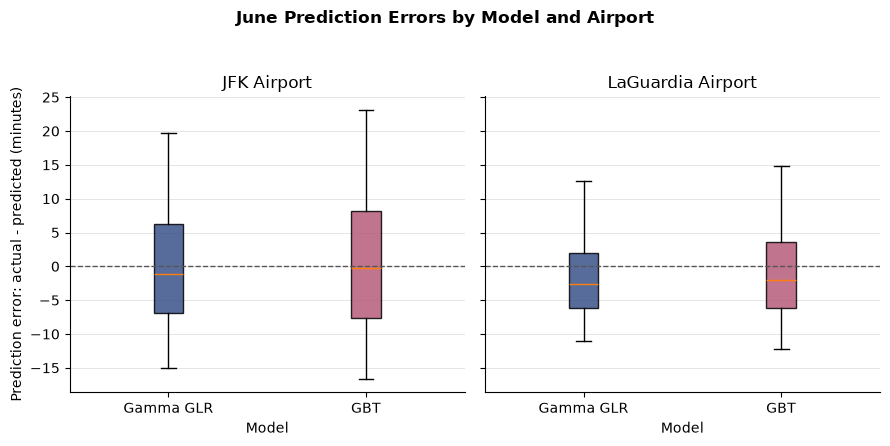

In [ ]:
error_plot_data = (june_prediction_errors.select("model", "airport", "prediction_error").toPandas())

model_order = selected_model_names
airport_order = ["JFK Airport", "LaGuardia Airport"]

model_colours = {"Gamma GLR": "#3B528B", "Gradient-Boosted Trees": "#B65C7A"}

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)

for axis, airport in zip(axes, airport_order):
    airport_data = error_plot_data.loc[error_plot_data["airport"] == airport]
    
    boxplot = axis.boxplot([airport_data.loc[airport_data["model"] == model, "prediction_error"]
                            for model in model_order],
                            tick_labels=["Gamma GLR", "GBT"],
                            patch_artist=True,
                            showfliers=False,
                            whis=(5, 95))
    
    for box, model in zip(boxplot["boxes"], model_order):
        box.set_facecolor(model_colours[model])
        box.set_alpha(0.85)
        
    axis.axhline(0,
                color="#555555",
                linestyle="--",
                linewidth=1)
    
    axis.set_title(airport)
    axis.set_xlabel("Model")
    axis.grid(axis="y", color="#E5E5E5", linewidth=0.7)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    
axes[0].set_ylabel("Prediction error: actual - predicted (minutes)")

fig.suptitle("June Prediction Errors by Model and Airport",
            fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig(PLOTS_DIR / "june_prediction_error_boxplot.pdf", bbox_inches="tight")

plt.show()

## Report Tables

In [ ]:
model_performance_summary = (
    april_screening_table.withColumn("evaluation_period", F.lit("April validation"))
    .unionByName(may_evaluation_summary.withColumn("evaluation_period", F.lit("May validation")))
    .unionByName(final_evaluation_summary.withColumn("evaluation_period", F.lit("June test")))
    .select("evaluation_period", "model", "mae", "rmse", "r2", "mean_underprediction")
    .withColumn("period_order", F.when(F.col("evaluation_period") == "April validation", 1)
                .when(F.col("evaluation_period") == "May validation", 2).otherwise(3)
            )
    .orderBy("period_order", "mae")
    .drop("period_order")
)

In [ ]:
model_performance_table = (model_performance_summary.toPandas()
                    .rename(columns={"evaluation_period": "Evaluation period",
                                    "model": "Model",
                                    "mae": "MAE",
                                    "rmse": "RMSE",
                                    "r2": "$R^2$",
                                    "mean_underprediction": "Mean underprediction"}))

weather_removal_table = (weather_removal_summary.toPandas()
                .rename(columns={"model": "Model",
                                "mae": "MAE",
                                "rmse": "RMSE",
                                "r2": "$R^2$",
                                "mean_underprediction": "Mean underprediction"}))

travel_time_buffer_table = (buffer_summary_display.toPandas()
                    .rename(columns={"model": "Model",
                                    "buffer_minutes": "Buffer (minutes)",
                                    "mean_prediction": "Mean prediction",
                                    "mean_recommended_minutes": "Mean recommended time",
                                    "june_coverage_percent": "June coverage (\\%)"}))

model_performance_table.to_latex(TABLES_DIR / "model_performance_summary.tex", index=False, escape=False)

weather_removal_table.to_latex(TABLES_DIR / "weather_removal_summary.tex", index=False, escape=False)

travel_time_buffer_table.to_latex(TABLES_DIR / "travel_time_buffer_summary.tex", index=False, escape=False)
print("Report tables saved")

## Cleanup

In [ ]:
for model_results in [april_model_results, may_model_results, final_model_results]:
    for result in model_results.values():
        result["predictions"].unpersist()
        
spark.catalog.clearCache()

print("Cached model data released")